Which pooled model best accounts for the observed recall sequences, and where do the models differ in what they predict? Compare likelihoods on the same trials, then compare saved responses with the observations.

<div id="notebook-reference">

| Parameter | Meaning |
| --- | --- |
| `fit_paths`, `model_labels` | Name at least two pooled likelihood fits and their optional display labels. The fits must use the same trials, objective, and stopping rule. |
| `simulation_paths` | Response HDF5 files keyed by fit name. A JSON file with the same stem records how each simulation was generated. |
| `project_root`, `data_path`, `output_dir` | Project directory for relative paths, HDF5 observation file, and output directory. |
| `enable_x64` | Use 64-bit JAX calculations. |
| `comparison_analysis_configs`, `single_analysis_configs` | Plot the requested analyses with the datasets overlaid or separately. Each entry names an analysis plotter and can supply its arguments and trial query. An empty list skips that set of figures. |
| `analysis_trial_query`, `filter_repeated_recalls` | Select trials for the figures and optionally remove repeated responses before plotting. |
| `confidence_level`, `plot_seed` | Confidence level and bootstrap seed for participant summaries. |
| `redo_figures`, `figure_dir`, `figure_str` | Draw the figures, choose their directory, and set the filename stem. An empty stem displays figures without saving. |
| `figure_size`, `figure_formats` | Figure width and height in inches and the file formats to save. |

`model_parameters.csv` lists fixed and estimated parameters. `pooled_model_comparison.csv` gives each model’s negative log likelihood, free-parameter count, AIC, and difference from the lowest AIC. Both are written under `output_dir`. Figures go under `figure_dir` or `output_dir`.

</div>

## Configure this run

In [1]:
#| code-summary: "Choose pooled fits, predictions, and figures"

# Files and directories
project_root = None  # Explicit folder, enclosing Git root, or current directory.
data_path = "data/Dupertuys2026.h5"
output_dir = "results/model_comparison"

# Saved fits
fit_paths = {
    "CMR": "data/fits/Dupertuys2026_CMR_demo.json",
    "eCMR_source_only": "data/fits/Dupertuys2026_eCMR_source_only.json",
    "eCMR_broad": "data/fits/Dupertuys2026_eCMR_broad.json",
}
simulation_paths = {
    "CMR": "data/simulations/Dupertuys2026_CMR_demo_best_of_3.h5",
    "eCMR_source_only": "data/simulations/Dupertuys2026_eCMR_source_only_demo_best_of_3.h5",
    "eCMR_broad": "data/simulations/Dupertuys2026_eCMR_broad_demo_best_of_3.h5",
}
model_labels = {
    "CMR": "CMR",
    "eCMR_source_only": "Source-only eCMR",
    "eCMR_broad": "Broader eCMR",
}

# Likelihood precision
enable_x64 = True

# Behavioral figures
confidence_level = 0.95
plot_seed = 0
comparison_analysis_configs = [
    {"target": "jaxcmr.analyses.spc.plot_spc", "title": "Recall by study position"},
    {
        "target": "jaxcmr.analyses.pnr.plot_pnr",
        "title": "First recall",
        "kwargs": {"query_recall_position": 0},
    },
    {
        "target": "jaxcmr.analyses.crp.plot_crp",
        "title": "Temporal transitions",
        "kwargs": {"max_lag": 5},
    },
    {
        "target": "jaxcmr.analyses.cat_recall_rate.plot_cat_recall_rate",
        "title": "Category recall within mixed lists",
        "contrast_name": "Item category",
        "trial_query": "data['list_type'] == 1",
        "kwargs": {
            "category_field": "valence",
            "category_values": [-1, 0],
            "category_labels": ["Emotional", "Neutral"],
            "valid_field": "pres_itemnos",
        },
    },
]
single_analysis_configs = []
analysis_trial_query = "jnp.all(data['pres_itemnos'] > 0, 1)"
filter_repeated_recalls = False
redo_figures = True

# Output locations and figure settings
figure_dir = None
figure_str = "model_and_data"  # Empty displays figures without saving.
figure_formats = ["png"]
figure_size = (10, 4.8)

## Load fits and identify shared trials

In [ ]:
#| code-summary: "Install JAXCMR in Colab"

import sys

if "google.colab" in sys.modules:
    %pip install --upgrade "jaxcmr @ git+https://github.com/githubpsyche/jaxcmr.git@main"

In [4]:
#| code-summary: "Import dataset and model operations"

import csv
import json
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from tabulate import tabulate

from jaxcmr import repetition
from jaxcmr.examples import copy_example_inputs
from jaxcmr.models import model_factory_from_paths, recorded_policy_path
from jaxcmr.fitting import make_scipy_loss_fn
from jaxcmr.helpers import import_from_string
from jaxcmr.helpers import load_data
from jaxcmr.helpers import resolve_project_path, resolve_project_root
from jaxcmr.plotting import iter_analysis_figures, save_figure
from jaxcmr.summarize import aic_scores

In [6]:
#| code-summary: "Load the observation file"

root_path = resolve_project_root(project_root)

copy_example_inputs([data_path, *fit_paths.values()], base_dir=root_path)

jax.config.update("jax_enable_x64", enable_x64)
data_path = resolve_project_path(data_path, root_path)
output_dir = resolve_project_path(output_dir, root_path)
output_dir.mkdir(parents=True, exist_ok=True)
data = load_data(str(data_path))
data_source = (
    data_path.relative_to(root_path).as_posix()
    if data_path.is_relative_to(root_path)
    else str(data_path)
)
subjects = np.asarray(data["subject"]).ravel()

In [8]:
#| code-summary: "Read the pooled fit records"

records = {name: json.loads(resolve_project_path(path, root_path).read_text()) for name, path in fit_paths.items()}
# Older records use the previous import path for this likelihood.
for record in records.values():
    if record["loss_function"] == "jaxcmr.loss.transform_sequence_likelihood.ExcludeTerminationLikelihoodLoss":
        record["loss_function"] = "jaxcmr.loss.sequence_likelihood.ExcludeTerminationLikelihoodLoss"
display_labels = {name: model_labels.get(name, name) for name in records}

In [9]:
#| code-summary: "Identify shared observations and scoring rules"

if len(records) < 2:
    raise ValueError("Supply at least two pooled likelihood fits.")
first = next(iter(records.values()))
selected_rows = sorted(first["selected_trial_indices"])
if not selected_rows or len(set(selected_rows)) != len(selected_rows):
    raise ValueError(
        "Compare at least two pooled fits with a nonempty observation selection."
    )
for name, record in records.items():
    if record["fits"]["subject"] != [-1] or len(record["fitness"]) != 1:
        raise ValueError(f"{name} is not a single pooled fit.")
    if (
        record.get("data_path", data_source) != data_source
        or sorted(record["selected_trial_indices"]) != selected_rows
    ):
        raise ValueError(f"{name}: observations or selected rows differ.")
    if (
        record["loss_function"] != first["loss_function"]
        or recorded_policy_path(record["components"])
        != recorded_policy_path(first["components"])
    ):
        raise ValueError("These fits do not use a common objective and stopping rule.")
comparison_mask = (
    jnp.zeros(len(subjects), dtype=bool).at[jnp.asarray(selected_rows)].set(True)
)
print(len(selected_rows), "shared lists; objective:", first["loss_function"])
print("Stopping policy:", recorded_policy_path(first["components"]))

492 shared lists; objective: jaxcmr.loss.sequence_likelihood.ExcludeTerminationLikelihoodLoss
Stopping policy: jaxcmr.components.response.RecallUntilExhausted


## Compare likelihoods and AIC

Rescore each pooled estimate on the shared trials. AIC adds twice the number of free parameters to twice the negative log likelihood. The model with the lowest AIC has a difference of zero.

**About the saved example.** The tables and figures displayed here come from the original comparison. The bundled observations have since been corrected. Running the example now stops when the recalculated likelihood differs from the saved fit. See the [example fit notes](https://github.com/githubpsyche/jaxcmr/blob/main/data/fits/README.md) for the data and model changes.

In [10]:
#| code-summary: "Show and save fixed and estimated parameters"

parameter_rows = []
for name, record in records.items():
    parameter_rows += [
        {
            "Model": display_labels[name],
            "Parameter": key,
            "Role": "Estimated" if key in record["free"] else "Fixed",
            "Value": values[0],
            "Bounds": record["free"].get(key),
        }
        for key, values in record["fits"].items()
        if key != "subject"
    ]
print(tabulate(parameter_rows, headers="keys", floatfmt=".5g"))
with (output_dir / "model_parameters.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(parameter_rows[0]))
    writer.writeheader()
    writer.writerows(parameter_rows)

Model             Parameter                             Role           Value  Bounds
----------------  ------------------------------------  ---------  ---------  -------------------------------------------
CMR               learn_after_context_update            Fixed       0
CMR               allow_repeated_recalls                Fixed       0
CMR               encoding_drift_rate                   Estimated   0.6812    [2.220446049250313e-16, 0.9999999999999998]
CMR               start_drift_rate                      Estimated   0.85983   [2.220446049250313e-16, 0.9999999999999998]
CMR               recall_drift_rate                     Estimated   0.71899   [2.220446049250313e-16, 0.9999999999999998]
CMR               learning_rate                         Estimated   0.36462   [2.220446049250313e-16, 0.9999999999999998]
CMR               shared_support                        Estimated  22.651     [2.220446049250313e-16, 100.0]
CMR               item_support                          

In [5]:
#| code-summary: "Read vocabulary features used by a model"

def load_features(record):
    embedding_path = record.get("embedding_path")
    category_path = record.get("emotion_feature_path")
    embeddings = np.load(resolve_project_path(embedding_path, root_path)) if embedding_path else None
    categories = None
    if category_path:
        column = int(record.get("feature_column", 6))
        categories = np.load(resolve_project_path(category_path, root_path))[:, column : column + 1]
    if record.get("concat_features"):
        return np.concatenate([categories, embeddings], axis=1)
    return categories if categories is not None else embeddings

In [11]:
#| code-summary: "Rescore each fit on the shared trials"

recalculated = {}
for name, record in records.items():
    model_factory = model_factory_from_paths(record["model_factory"], record["components"])
    features = load_features(record)
    loss_class = import_from_string(record["loss_function"])
    fixed = (
        record.get("fit_configuration", {})
        .get("parameters", {})
        .get("fixed", record["fixed"])
    )
    names = tuple(record["free"])
    evaluate = make_scipy_loss_fn(
        loss_class(model_factory, data, features),
        jnp.asarray(selected_rows),
        fixed,
        names,
    )
    values = jnp.asarray([record["fits"][key][0] for key in names])
    recalculated[name] = float(evaluate(values))
    if not np.isclose(recalculated[name], record["fitness"][0], rtol=1e-6, atol=1e-5):
        raise ValueError(
            f"{name}: saved NLL {record['fitness'][0]:.6f}, "
            f"recalculated NLL {recalculated[name]:.6f}."
        )
print(
    tabulate(
        [
            {
                "Model": display_labels[name],
                "Saved NLL": record["fitness"][0],
                "Recalculated NLL": recalculated[name],
            }
            for name, record in records.items()
        ],
        headers="keys",
        floatfmt=".6f",
    )
)

Model               Saved NLL    Recalculated NLL
----------------  -----------  ------------------
CMR               7202.029122         7202.029122
Source-only eCMR  7169.426270         7169.426270
Broader eCMR      7164.357873         7164.357873


In [12]:
#| code-summary: "Calculate and save the pooled AIC comparison"

# Each pooled fit incurs one penalty, using its unscaled negative log likelihood.
comparison = [
    {
        "Model": display_labels[name],
        "Free parameters": len(record["free"]),
        "Negative log likelihood": recalculated[name],
        "AIC": float(aic_scores(recalculated[name], len(record["free"]))),
    }
    for name, record in records.items()
]
best = min(row["AIC"] for row in comparison)
for row in comparison:
    row["Delta AIC"] = row["AIC"] - best
print(tabulate(comparison, headers="keys", floatfmt=".3f"))
with (output_dir / "pooled_model_comparison.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(comparison[0]))
    writer.writeheader()
    writer.writerows(comparison)

Model               Free parameters    Negative log likelihood        AIC    Delta AIC
----------------  -----------------  -------------------------  ---------  -----------
CMR                               9                   7202.029  14422.058       73.342
Source-only eCMR                 10                   7169.426  14358.853       10.137
Broader eCMR                     10                   7164.358  14348.716        0.000


In [13]:
#| code-summary: "Show available search histories"

search_rows = []
for model_name, fit_record in records.items():
    for run in fit_record.get("search_comparison", {}).get("runs", []):
        search_rows.append(
            {
                "Model": display_labels[model_name],
                "Seed": run["seed"],
                "NLL": run["nll"],
            }
        )
if search_rows:
    print(tabulate(search_rows, headers="keys", floatfmt=".6f"))

Model               Seed          NLL
----------------  ------  -----------
CMR                    0  7202.114181
CMR                    1  7202.029122
Source-only eCMR       0  7169.430814
Source-only eCMR       1  7169.426270
Broader eCMR           0  7164.357873
Broader eCMR           1  7164.407215


## Compare predicted and observed recall

The figures compare observations with responses generated from the fitted parameters. The analysis query can narrow the selection for a figure. If the simulator imposes observed recall counts, agreement in recall length is built into the predictions.

In [14]:
#| code-summary: "Load the predictions and check their fit records"

simulations = {}
if redo_figures and (comparison_analysis_configs or single_analysis_configs):
    response_inputs = [simulation_paths[name] for name in records]
    settings_paths = [str(Path(path).with_suffix(".json")) for path in response_inputs]
    copy_example_inputs([*response_inputs, *settings_paths], base_dir=root_path)
    for name, record in records.items():
        path = resolve_project_path(simulation_paths[name], root_path)
        metadata = json.loads(path.with_suffix(".json").read_text())
        expected = {
            "data_path": data_source,
            "selected_trial_indices": selected_rows,
            "fits": record["fits"],
            "model_factory": record["model_factory"],
            "components": record["components"],
            "simulation_function": record["simulation_function"],
        }
        if any(metadata.get(key) != value for key, value in expected.items()):
            raise ValueError(
                f"{name}: saved responses belong to a different fit or observation selection."
            )
        simulated = load_data(str(path))
        if filter_repeated_recalls:
            simulated = simulated.copy()
            simulated["recalls"] = repetition.filter_repeated_recalls(simulated["recalls"])
        simulations[name] = simulated

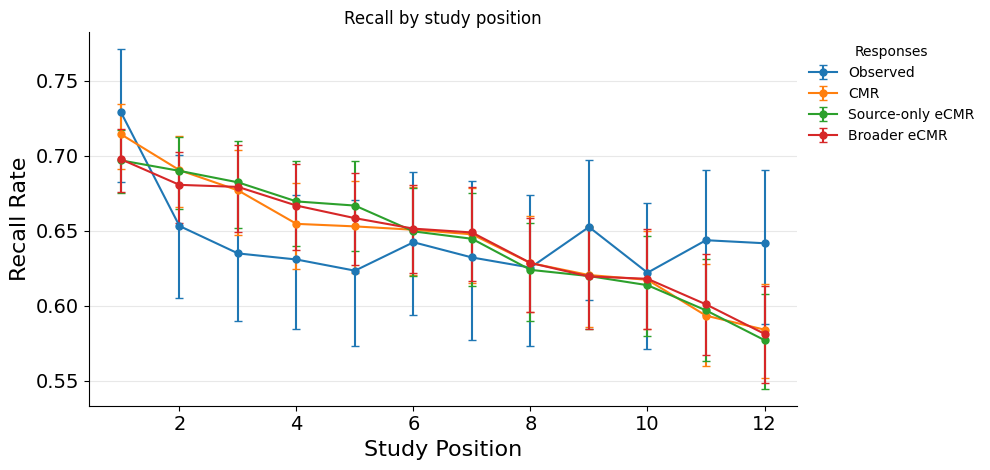

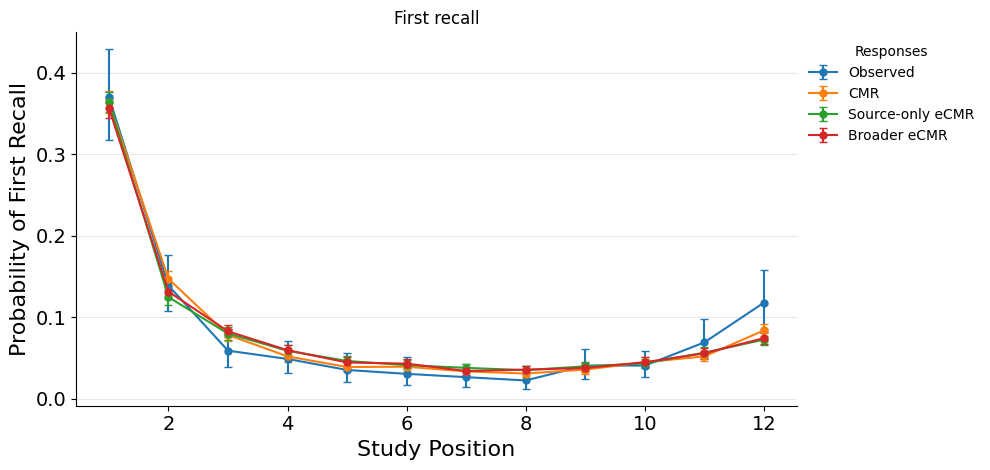

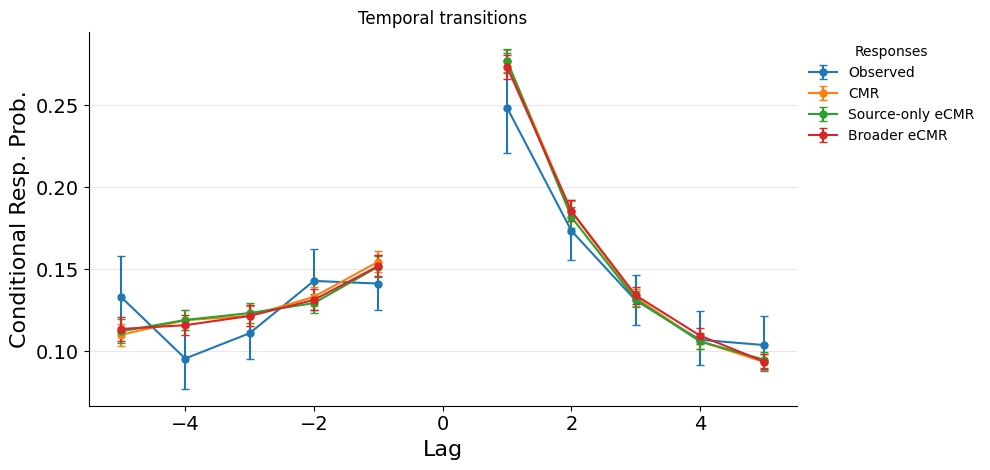

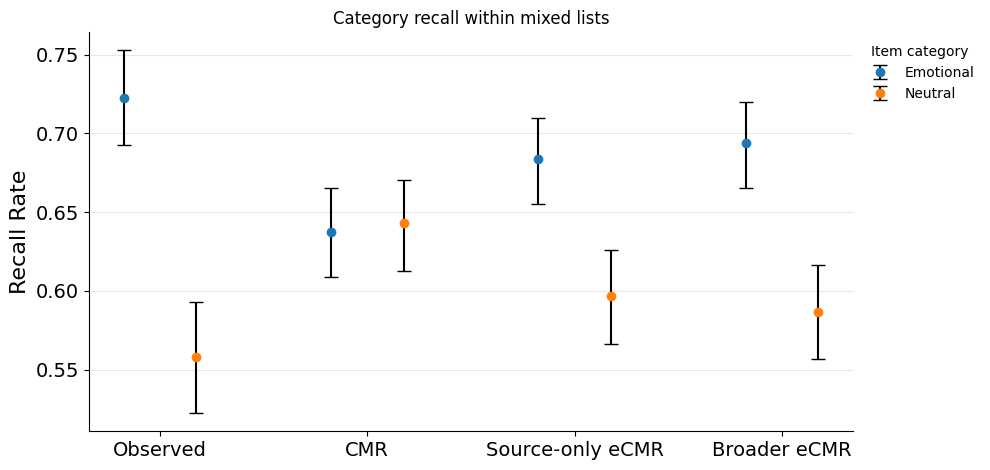

In [16]:
#| code-summary: "Draw and save each prediction comparison"

figure_dir = resolve_project_path(figure_dir, root_path) if figure_dir else output_dir
if simulations:
    observed = data.copy()
    if filter_repeated_recalls:
        observed["recalls"] = repetition.filter_repeated_recalls(observed["recalls"])
    datasets = [observed, *simulations.values()]
    labels = ["Observed", *[display_labels[name] for name in simulations]]
    masks = [comparison_mask, *[None for _ in simulations]]

    comparisons = [(comparison_analysis_configs, datasets, labels, masks, "")]
    if single_analysis_configs:
        for index, (dataset, label, mask) in enumerate(zip(datasets, labels, masks, strict=True)):
            comparisons.append((single_analysis_configs, [dataset], [label], [mask], f"_single_{index}"))

    for analyses, responses, curve_labels, trial_masks, suffix in comparisons:
        for figure, filename_suffix in iter_analysis_figures(
            responses, analyses, curve_labels, base_masks=trial_masks, suffix=suffix,
            trial_query=analysis_trial_query, confidence_level=confidence_level,
            figure_size=figure_size, bootstrap_seed=plot_seed,
        ):
            if figure_str:
                save_figure(figure_dir, figure_str, suffix=filename_suffix,
                            formats=figure_formats, figure=figure)
            else:
                figure.tight_layout()
            plt.show()
            plt.close(figure)